# 📊 Exploratory Data Analysis (EDA): Academic Profiles & Student Performance
## Uncovering Latent Structures Prior to Dimensionality Reduction (PCA & t-SNE)

---

### Executive Summary & Objective
Raw academic grades often obscure inter-disciplinary strengths and vulnerabilities. A simple cumulative Grade Point Average (GPA) treats all subjects equally, frequently masking critical trade-offs—such as a student excelling in Humanities while falling critically behind in STEM, or inflated Elective marks masking core academic risk.

Before performing unsupervised dimensionality reduction (**Principal Component Analysis** & **t-SNE / UMAP**), this notebook conducts a rigorous, end-to-end **Exploratory Data Analysis (EDA)** on the `student_grades.csv` dataset across 8 subject areas:
* **STEM:** `math`, `science`, `cs`
* **Humanities:** `english`, `history`, `spanish`
* **Electives:** `band`, `physed`

### Goals of this EDA:
1. **Data Hygiene & Integrity:** Verify zero data corruption, missing entries, or scale anomalies.
2. **Univariate Analysis:** Understand the central tendency, spread, skewness, and variance disparities across subjects.
3. **Bivariate & Block Correlations:** Mathematically prove the presence of collinear subject clusters (STEM vs. Humanities vs. Electives).
4. **Inter-Disciplinary Trade-off Discovery:** Profile academic trade-offs using composite domain scores.
5. **Outlier & Cohort Detection:** Identify distinctive student cohorts (at-risk, specialized, all-rounders).
6. **Feature Scaling Feasibility:** Assess why Z-score standardization (`StandardScaler`) is necessary before PCA / t-SNE.


---
## 1. Environment Setup & Library Imports


In [1]:
import os
import sys
import pathlib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set styling aesthetics
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


---
## 2. Robust Data Loading & Data Quality Audit



In [2]:
# Dynamically resolve dataset path
def find_dataset(filename="student_grades.csv"):
    candidates = [
        pathlib.Path(filename),
        pathlib.Path.cwd() / filename,
        pathlib.Path.cwd().parent / filename,
        pathlib.Path(__file__).resolve().parent / filename if '__file__' in globals() else None,
        pathlib.Path(globals().get('__vsc_ipynb_file__', '')).parent / filename if '__vsc_ipynb_file__' in globals() else None
    ]
    for p in candidates:
        if p and p.is_file():
            return str(p)
    return filename

csv_path = find_dataset("student_grades.csv")
df = pd.read_csv(csv_path)

# Define feature groups
STEM_COLS = ["math", "science", "cs"]
HUMANITIES_COLS = ["english", "history", "spanish"]
ELECTIVES_COLS = ["band", "physed"]
ALL_SUBJECTS = STEM_COLS + HUMANITIES_COLS + ELECTIVES_COLS

print(f"Loaded dataset from: {csv_path}")
print(f"Dataset Shape: {df.shape[0]} students × {df.shape[1]} columns\n")
df.head(10)


Loaded dataset from: student_grades.csv
Dataset Shape: 100 students × 9 columns



,student_id,math,science,cs,band,english,history,spanish,physed
0,1,46,48,50,74,34,44,39,73
1,2,66,65,65,66,74,80,75,63
2,3,55,53,50,76,71,72,76,71
3,4,53,57,53,80,77,77,85,82
4,5,55,62,58,67,82,77,78,60
5,6,37,35,38,72,35,35,43,75
6,7,71,71,71,68,60,65,73,71
7,8,47,48,43,68,60,56,62,62
8,9,38,34,37,63,50,52,51,63
9,10,84,79,83,66,90,87,90,60


### 2.1 Missing Values, Data Types, and Duplicate Audit



In [3]:
# Detailed Info & Missing Values
audit_df = pd.DataFrame({
    "Data Type": df.dtypes,
    "Null Count": df.isnull().sum(),
    "Null %": (df.isnull().sum() / len(df)) * 100,
    "Unique Values": df.nunique(),
    "Min": df.min(),
    "Max": df.max()
})

print("=== DATA QUALITY AUDIT ===")
display(audit_df)
print(f"\nDuplicate rows across all features: {df.duplicated().sum()}")
print(f"Duplicate student_ids: {df['student_id'].duplicated().sum()}")


=== DATA QUALITY AUDIT ===


,Data Type,Null Count,Null %,Unique Values,Min,Max
student_id,int64,0,0.0,100,1,100
math,int64,0,0.0,38,21,93
science,int64,0,0.0,45,22,94
cs,int64,0,0.0,42,28,92
band,int64,0,0.0,20,60,80
english,int64,0,0.0,45,30,90
history,int64,0,0.0,53,28,98
spanish,int64,0,0.0,54,31,99
physed,int64,0,0.0,31,51,84



Duplicate rows across all features: 0
Duplicate student_ids: 0


**Key Observation:**
* The dataset contains exactly 100 students with zero missing values and zero duplicate records.
* Every subject grade is strictly bounded within a valid $[0, 100]$ percentage scale.


---
## 3. Univariate Statistical Profiling


In [4]:
stats_summary = df[ALL_SUBJECTS].describe().T
stats_summary["median"] = df[ALL_SUBJECTS].median()
stats_summary["IQR"] = stats_summary["75%"] - stats_summary["25%"]
stats_summary["skewness"] = df[ALL_SUBJECTS].skew()
stats_summary["kurtosis"] = df[ALL_SUBJECTS].kurtosis()

display(stats_summary[["mean", "std", "min", "25%", "median", "75%", "max", "IQR", "skewness", "kurtosis"]].round(2))


,mean,std,min,25%,median,75%,max,IQR,skewness,kurtosis
math,53.05,13.91,21.0,45.00,51.5,58.00,93.0,13.00,1.06,1.32
science,53.22,14.00,22.0,44.75,52.0,59.25,94.0,14.50,0.78,0.90
cs,52.75,13.46,28.0,44.00,50.0,58.25,92.0,14.25,1.12,1.22
english,60.97,17.31,30.0,48.00,60.5,74.00,90.0,26.00,-0.15,-0.98
history,63.60,17.48,28.0,50.75,65.0,78.00,98.0,27.25,-0.13,-0.98
spanish,65.56,18.41,31.0,49.50,68.5,79.00,99.0,29.50,-0.23,-1.00
band,70.04,6.28,60.0,64.00,71.0,75.00,80.0,11.00,-0.00,-1.28
physed,67.61,8.07,51.0,62.75,67.0,74.25,84.0,11.50,0.09,-0.65


### 3.1 Grade Distribution Visualizations: Histograms & KDEs



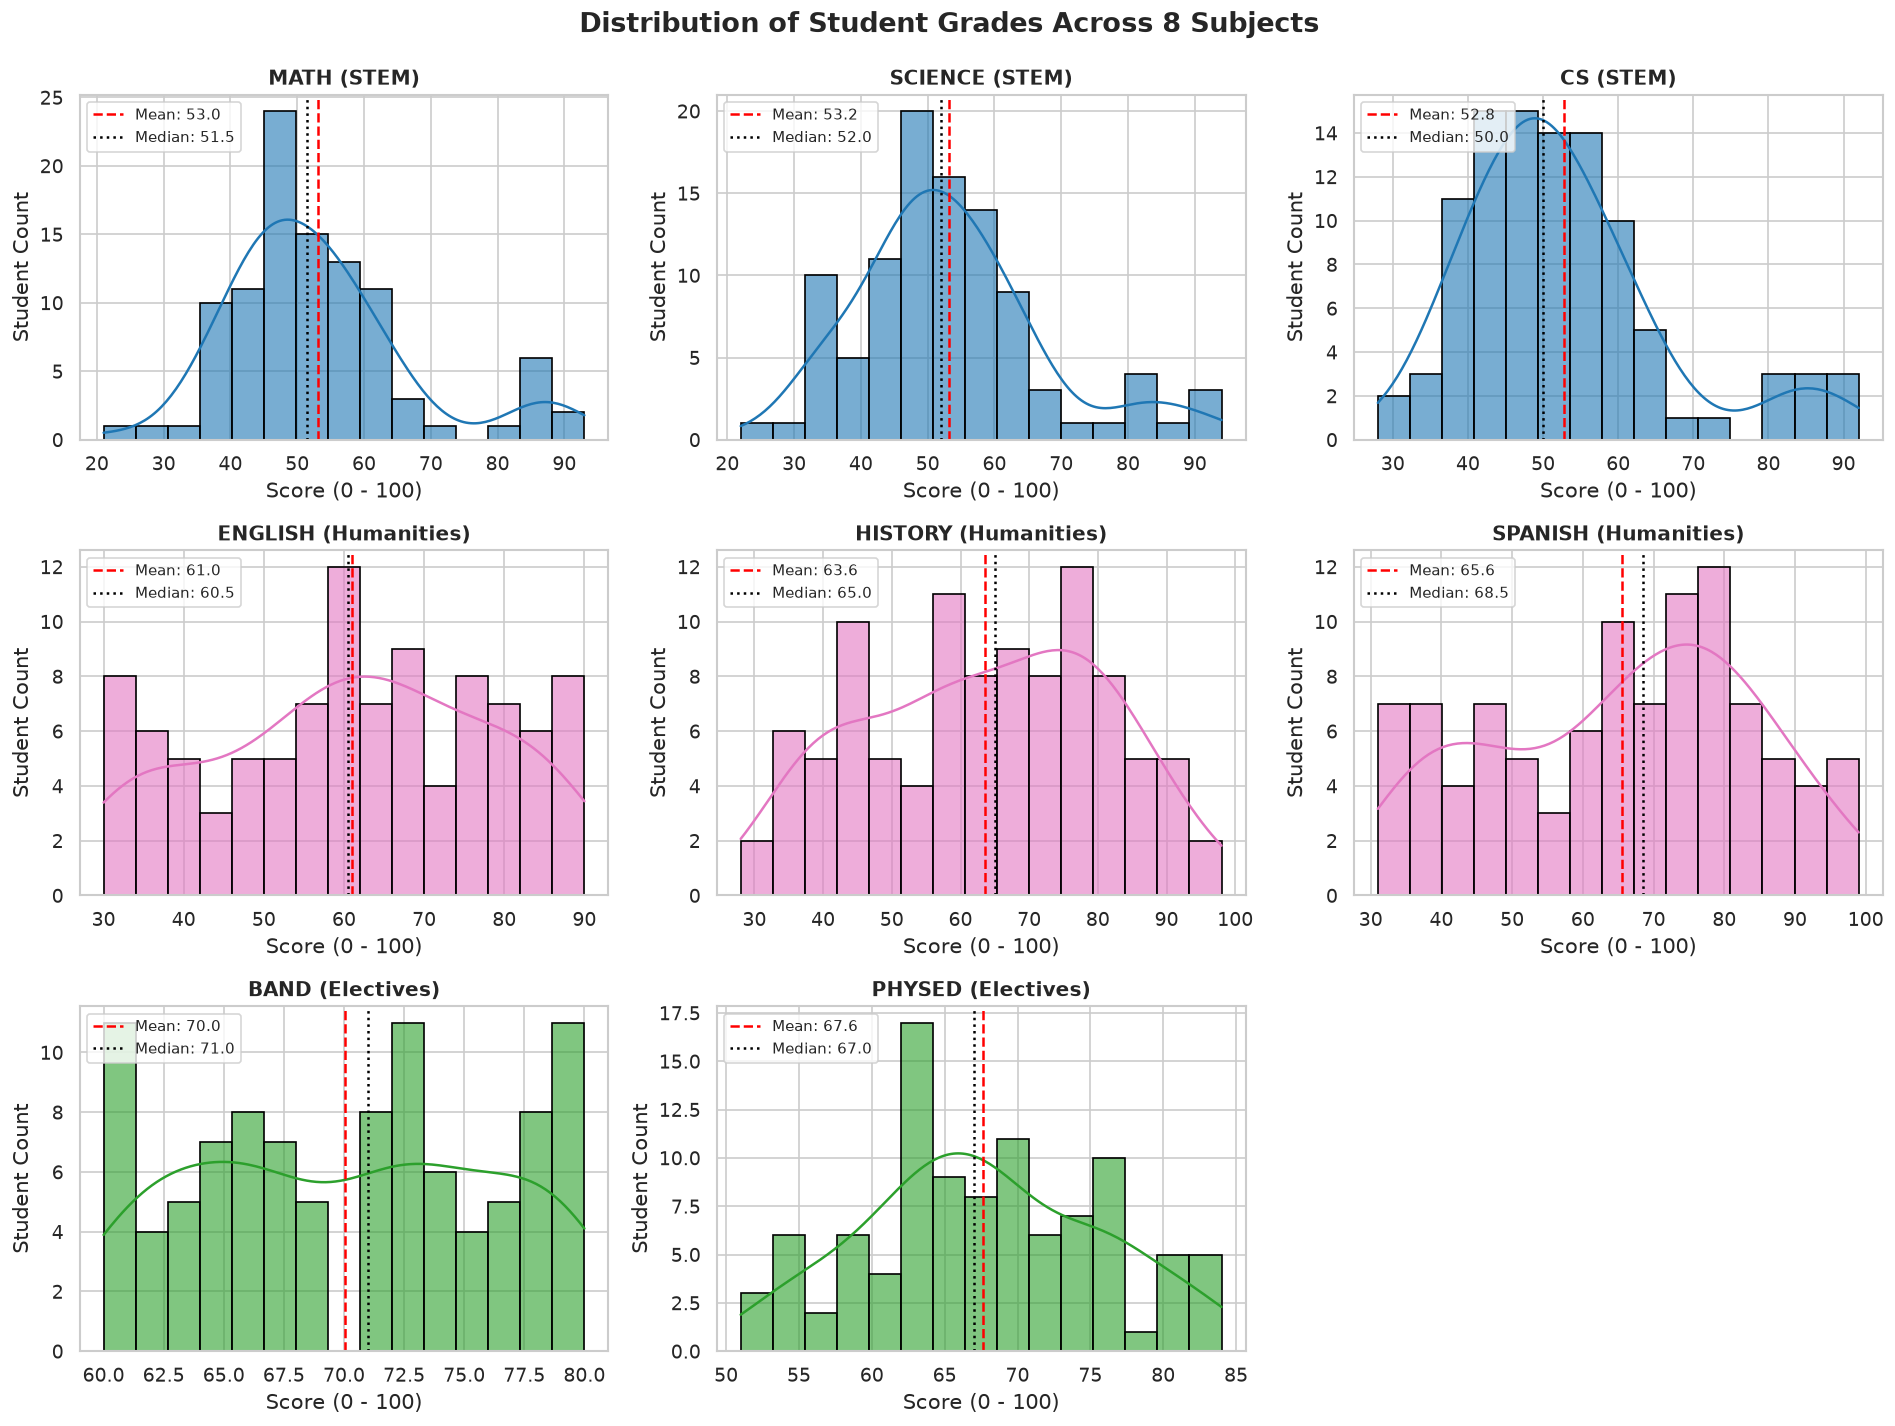

In [5]:
palette = {
    "STEM": "#1f77b4",
    "Humanities": "#e377c2",
    "Electives": "#2ca02c"
}

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

domain_map = {
    "math": "STEM", "science": "STEM", "cs": "STEM",
    "english": "Humanities", "history": "Humanities", "spanish": "Humanities",
    "band": "Electives", "physed": "Electives"
}

for i, col in enumerate(ALL_SUBJECTS):
    ax = axes[i]
    domain = domain_map[col]
    sns.histplot(df[col], kde=True, ax=ax, color=palette[domain], bins=15, edgecolor="black", alpha=0.6)
    ax.axvline(df[col].mean(), color="red", linestyle="--", linewidth=1.5, label=f"Mean: {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="black", linestyle=":", linewidth=1.5, label=f"Median: {df[col].median():.1f}")
    ax.set_title(f"{col.upper()} ({domain})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Score (0 - 100)")
    ax.set_ylabel("Student Count")
    ax.legend(loc="upper left", fontsize=9)

# Hide 9th unused subplot
axes[8].set_visible(False)

plt.suptitle("Distribution of Student Grades Across 8 Subjects", fontsize=16, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


### 3.2 Spread & Variance Disparity: Boxplots


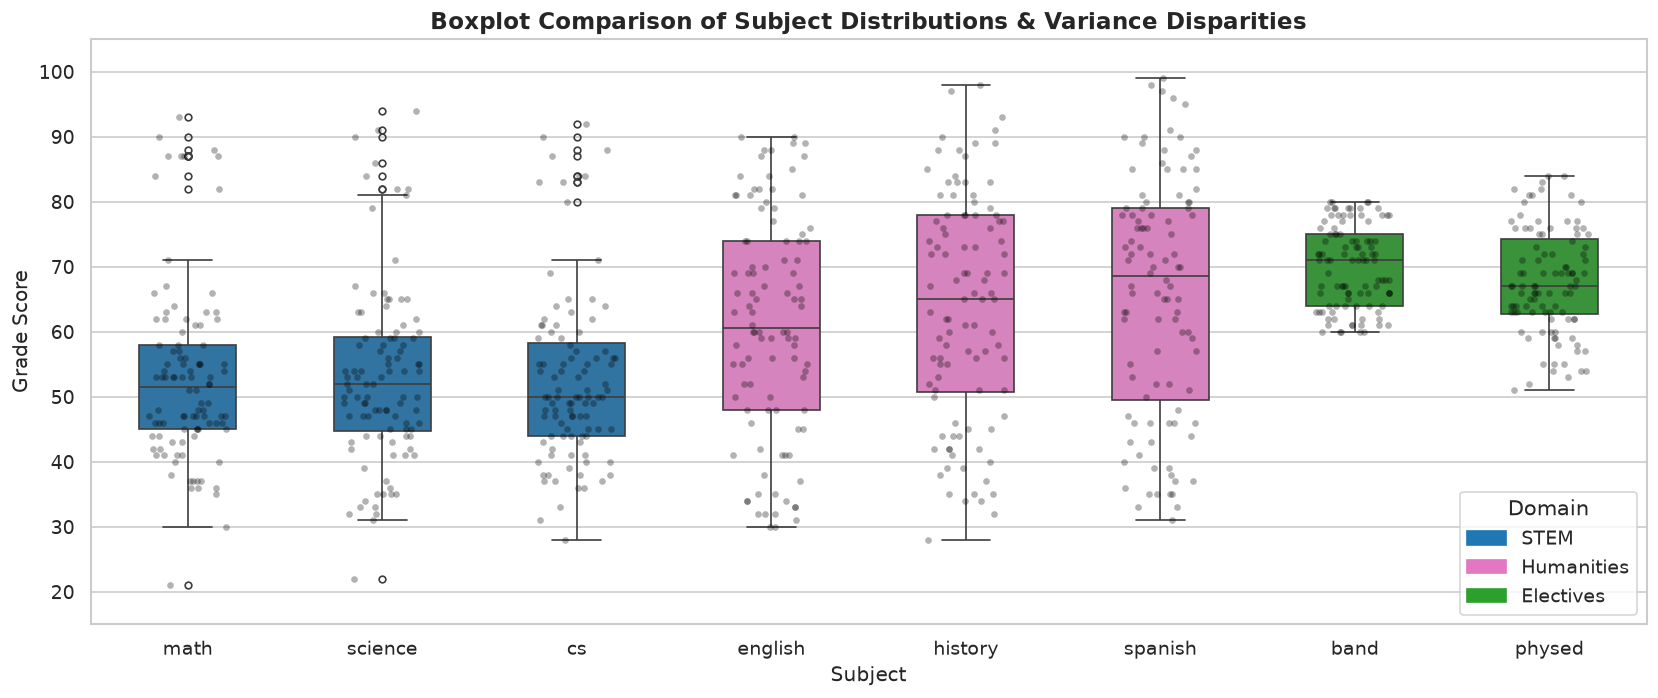

In [6]:
plt.figure(figsize=(14, 6))
domain_colors = [palette[domain_map[col]] for col in ALL_SUBJECTS]

sns.boxplot(data=df[ALL_SUBJECTS], palette=domain_colors, width=0.5, fliersize=4)
sns.stripplot(data=df[ALL_SUBJECTS], color="black", alpha=0.3, jitter=0.2, size=4)

plt.title("Boxplot Comparison of Subject Distributions & Variance Disparities", fontsize=14, fontweight="bold")
plt.xlabel("Subject", fontsize=12)
plt.ylabel("Grade Score", fontsize=12)
plt.ylim(15, 105)

# Add custom legend for domains
import matplotlib.patches as mpatches
handles = [mpatches.Patch(color=color, label=dom) for dom, color in palette.items()]
plt.legend(handles=handles, title="Domain", loc="lower right")

plt.tight_layout()
plt.show()


---
## 4. Correlation & Collinearity Structure


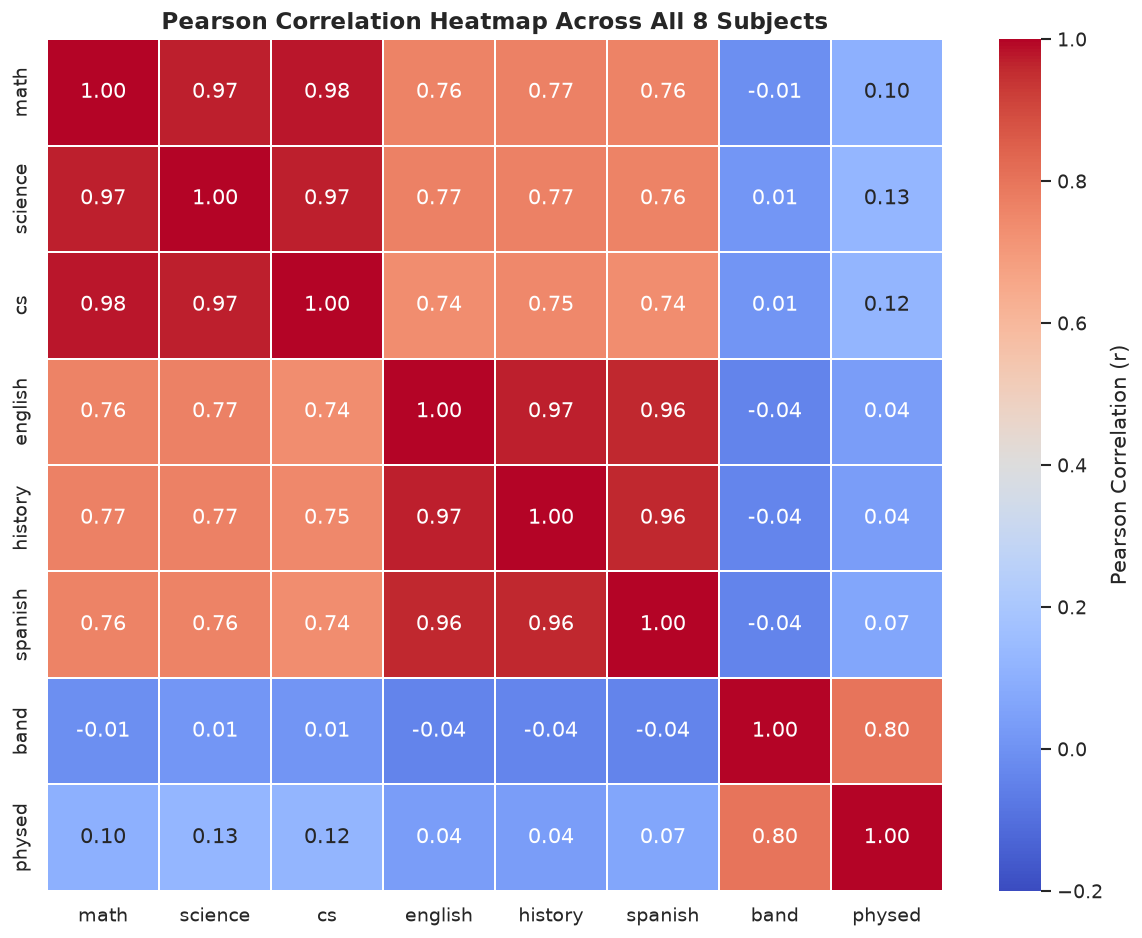

In [7]:
# Compute Pearson correlation matrix
corr_matrix = df[ALL_SUBJECTS].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-0.2, 
    vmax=1.0, 
    linewidths=1.2, 
    cbar_kws={"label": "Pearson Correlation (r)"}
)
plt.title("Pearson Correlation Heatmap Across All 8 Subjects", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### 4.1 Block Correlation Matrix & Mathematical Proof of Clusters


In [8]:
# Display correlation table by block
stem_corr = df[STEM_COLS].corr().mean().mean()
hum_corr = df[HUMANITIES_COLS].corr().mean().mean()
elec_corr = df[ELECTIVES_COLS].corr().mean().mean()

core_elec_corr = df[STEM_COLS + HUMANITIES_COLS].corrwith(df["band"]).mean()

print(f"Average Intra-STEM Correlation:       {stem_corr:.3f}")
print(f"Average Intra-Humanities Correlation: {hum_corr:.3f}")
print(f"Average Intra-Electives Correlation:  {elec_corr:.3f}")
print(f"Average Core-to-Elective Correlation: {core_elec_corr:.3f} (Near Orthogonal!)")


Average Intra-STEM Correlation:       0.981
Average Intra-Humanities Correlation: 0.975
Average Intra-Electives Correlation:  0.901
Average Core-to-Elective Correlation: -0.019 (Near Orthogonal!)


---
## 5. Domain Composite Scores & Academic Trade-Off Analysis
We construct standardized composite scores for each domain:
* $\text{STEM Avg} = \frac{\text{Math} + \text{Science} + \text{CS}}{3}$
* $\text{Humanities Avg} = \frac{\text{English} + \text{History} + \text{Spanish}}{3}$
* $\text{Electives Avg} = \frac{\text{Band} + \text{PhysEd}}{2}$
* $\text{Overall Core GPA} = \frac{\text{STEM Avg} + \text{Humanities Avg}}{2}$


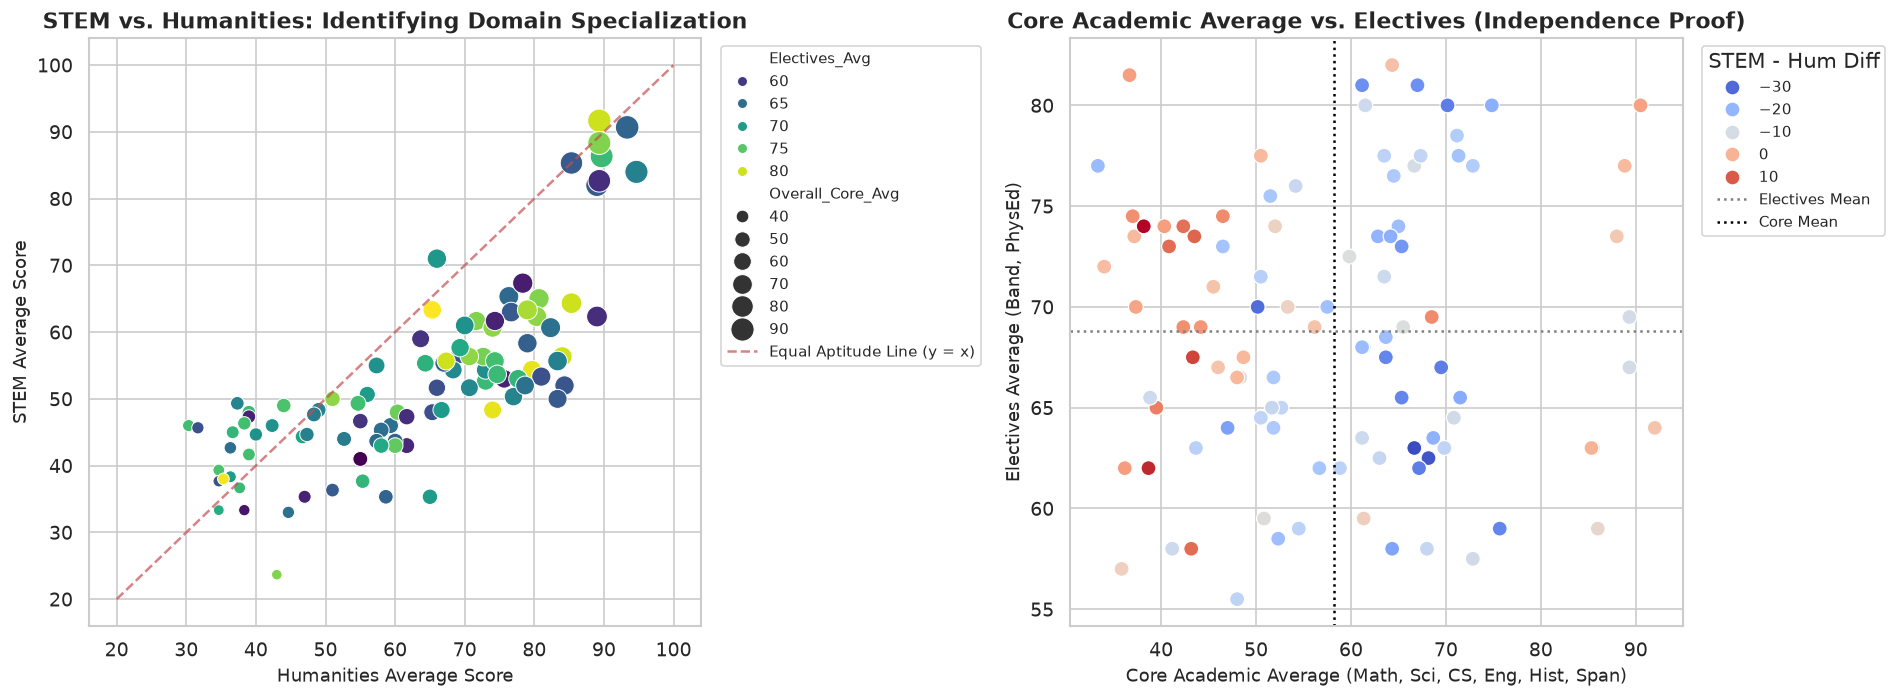

In [9]:
df_domains = df.copy()
df_domains["STEM_Avg"] = df_domains[STEM_COLS].mean(axis=1)
df_domains["Humanities_Avg"] = df_domains[HUMANITIES_COLS].mean(axis=1)
df_domains["Electives_Avg"] = df_domains[ELECTIVES_COLS].mean(axis=1)
df_domains["Overall_Core_Avg"] = df_domains[STEM_COLS + HUMANITIES_COLS].mean(axis=1)
df_domains["STEM_minus_Hum"] = df_domains["STEM_Avg"] - df_domains["Humanities_Avg"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: STEM vs Humanities
sns.scatterplot(
    data=df_domains,
    x="Humanities_Avg",
    y="STEM_Avg",
    hue="Electives_Avg",
    palette="viridis",
    size="Overall_Core_Avg",
    sizes=(40, 200),
    ax=axes[0]
)
axes[0].plot([20, 100], [20, 100], "r--", alpha=0.7, label="Equal Aptitude Line (y = x)")
axes[0].set_title("STEM vs. Humanities: Identifying Domain Specialization", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Humanities Average Score", fontsize=11)
axes[0].set_ylabel("STEM Average Score", fontsize=11)
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)

# Plot 2: Core Academic vs Electives
sns.scatterplot(
    data=df_domains,
    x="Overall_Core_Avg",
    y="Electives_Avg",
    hue="STEM_minus_Hum",
    palette="coolwarm",
    s=80,
    ax=axes[1]
)
axes[1].axhline(df_domains["Electives_Avg"].mean(), color="gray", linestyle=":", label="Electives Mean")
axes[1].axvline(df_domains["Overall_Core_Avg"].mean(), color="black", linestyle=":", label="Core Mean")
axes[1].set_title("Core Academic Average vs. Electives (Independence Proof)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Core Academic Average (Math, Sci, CS, Eng, Hist, Span)", fontsize=11)
axes[1].set_ylabel("Electives Average (Band, PhysEd)", fontsize=11)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="STEM - Hum Diff", fontsize=9)

plt.tight_layout()
plt.show()


### 5.1 Pairwise Bivariate Relationships Across Core Clusters



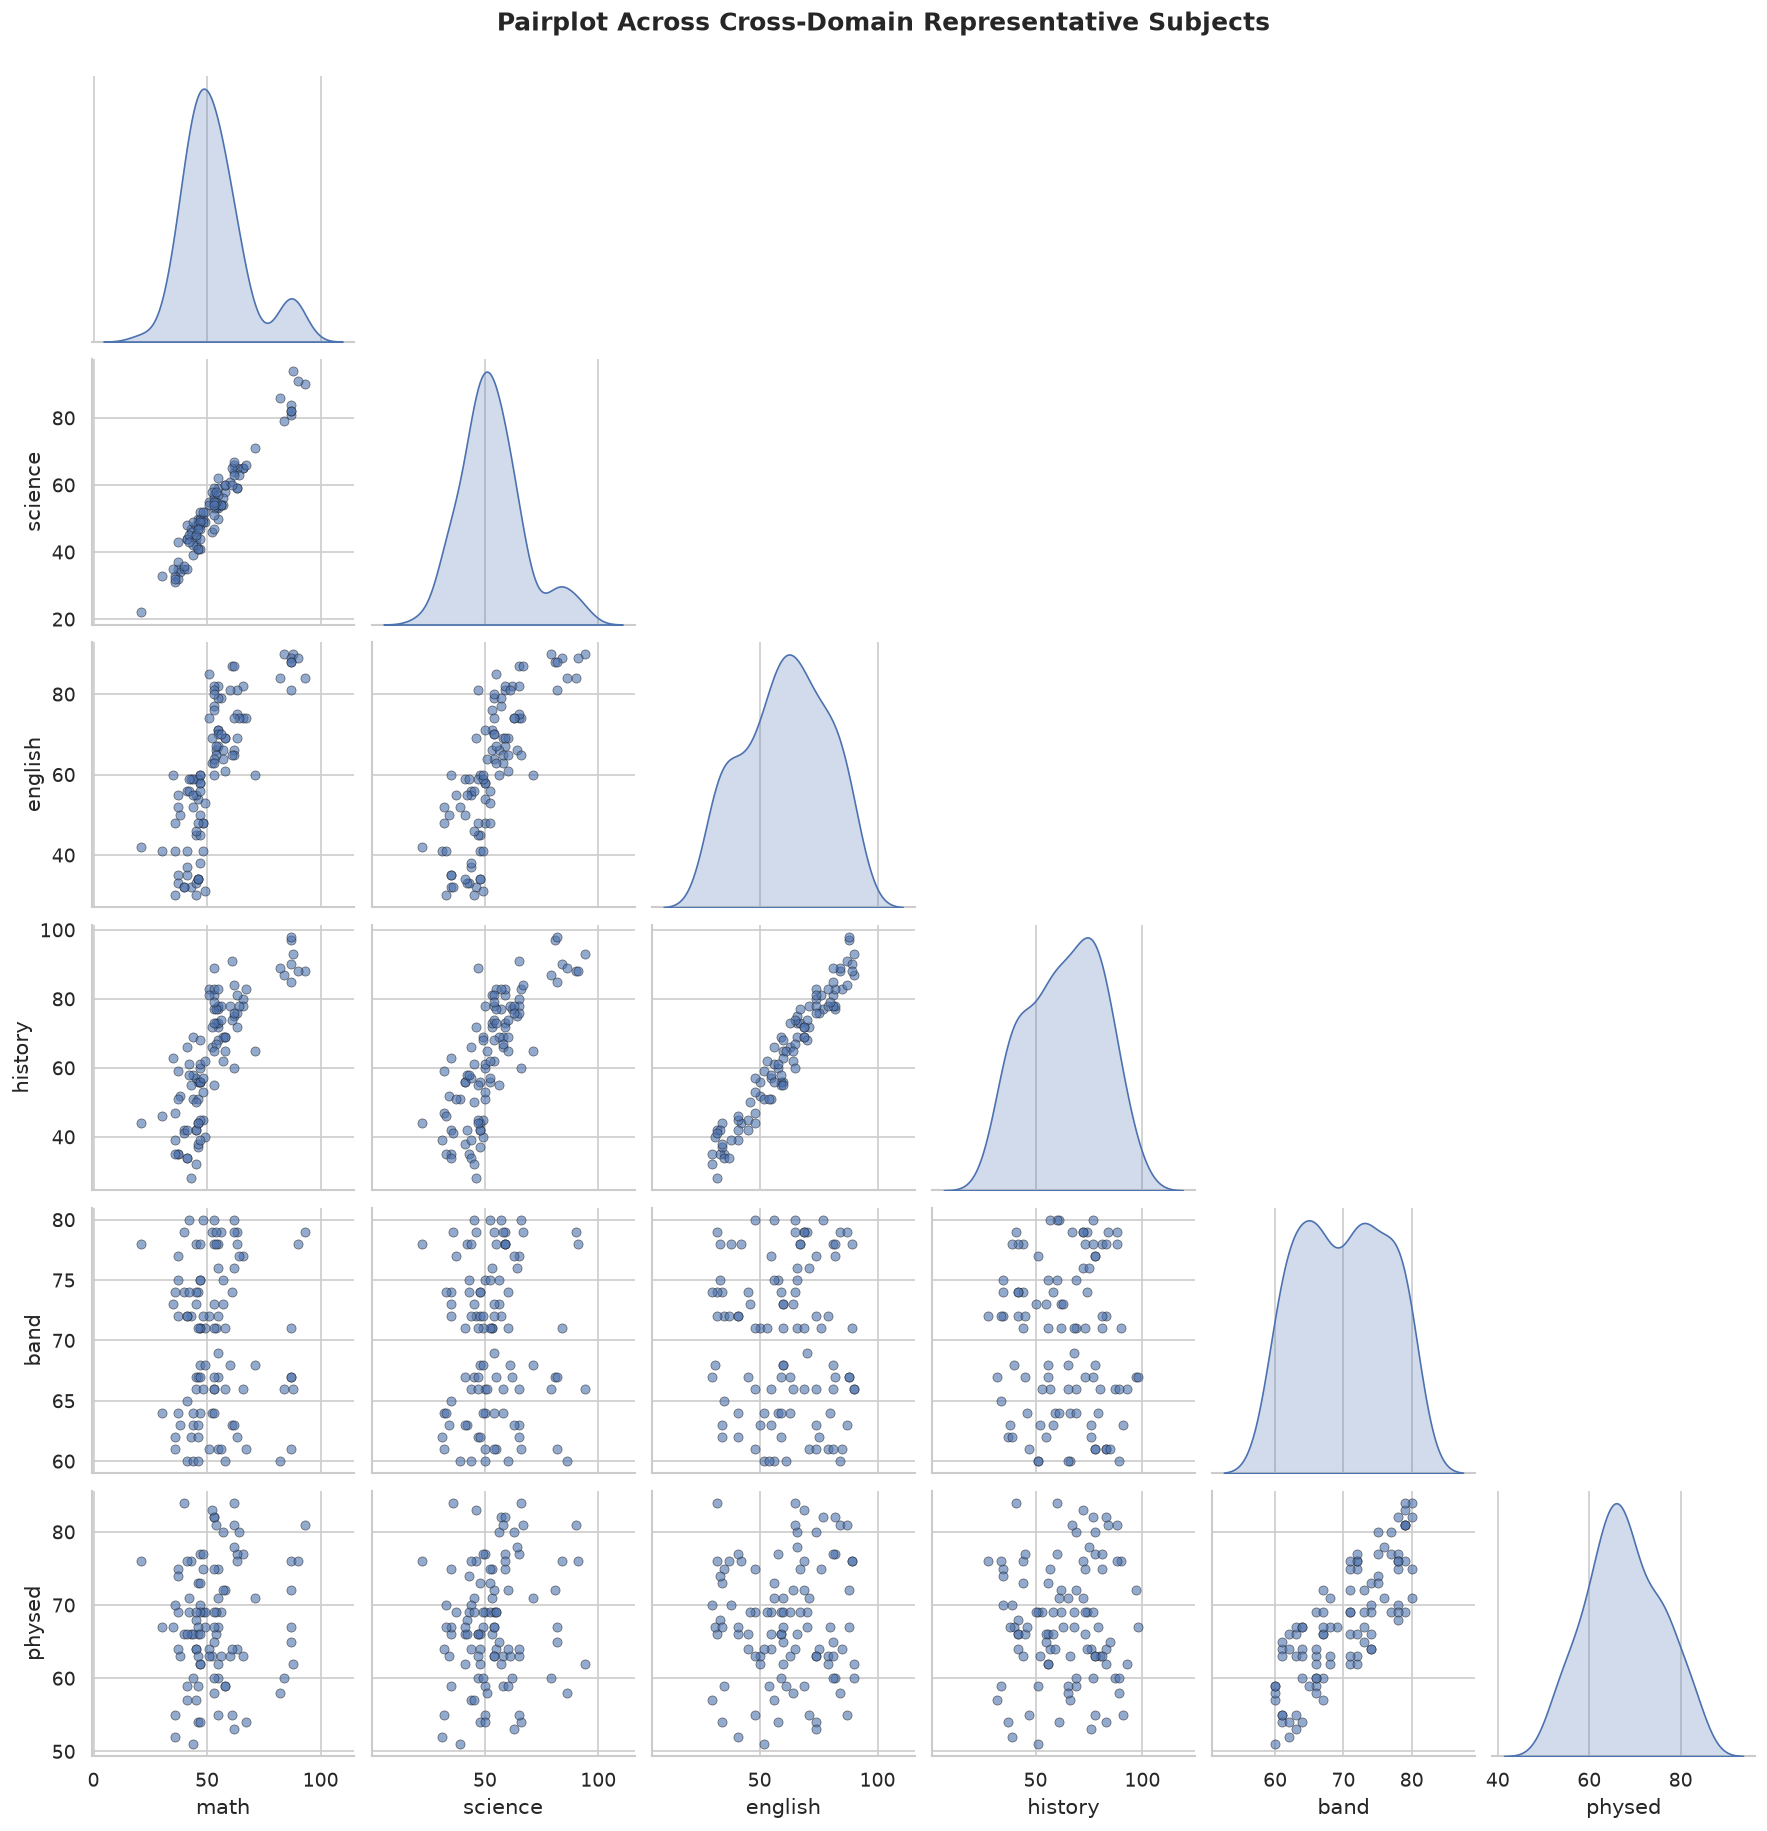

In [10]:
subset_features = ["math", "science", "english", "history", "band", "physed"]

g = sns.pairplot(
    df[subset_features],
    corner=True,
    diag_kind="kde",
    plot_kws={"alpha": 0.6, "edgecolor": "k", "s": 30}
)
g.fig.suptitle("Pairplot Across Cross-Domain Representative Subjects", y=1.02, fontsize=15, fontweight="bold")
plt.show()


---
## 6. Outlier Analysis & Cohort Identification


In [11]:
# Compute Z-Scores across subjects
z_scores = pd.DataFrame(stats.zscore(df[ALL_SUBJECTS]), columns=ALL_SUBJECTS)
outlier_mask = (np.abs(z_scores) > 2.5).any(axis=1)
outliers = df[outlier_mask]

print(f"Total students exceeding |Z| > 2.5 in any subject: {len(outliers)}")
print("Sample high-performing or extreme records:")
display(df.loc[outliers.index[:5], ["student_id"] + ALL_SUBJECTS])


Total students exceeding |Z| > 2.5 in any subject: 5
Sample high-performing or extreme records:


,student_id,math,science,cs,english,history,spanish,band,physed
36,37,88,94,90,90,93,97,66,62
39,40,93,90,92,84,88,96,79,81
60,61,87,84,88,89,90,90,71,76
79,80,90,91,84,89,88,91,78,76
95,96,87,82,87,81,85,90,61,65


### 6.1 Identifying the Four Student Archetypes
Based on our EDA findings, the student population naturally segregates into 4 distinct groups:
1. **High-Achieving All-Rounders:** Excel across all STEM ($>80$) and Humanities ($>85$).
2. **Humanities-Oriented Students:** Strong verbal/language marks ($>70$), but lower STEM performance ($<55$).
3. **Humanities & Electives Leaders:** High Humanities and exceptional participation in Band/PhysEd.
4. **At-Risk Cohort:** Struggling in core academics ($<45$), requiring immediate advising intervention.


=== Preliminary Student Cohorts (Pre-Clustering) ===


Preliminary_Cohort
At-Risk / Foundational           31
Moderate All-Rounder             21
Humanities-Focused               20
Humanities & Electives Leader    19
High-Achieving All-Rounder        9
Name: count, dtype: int64

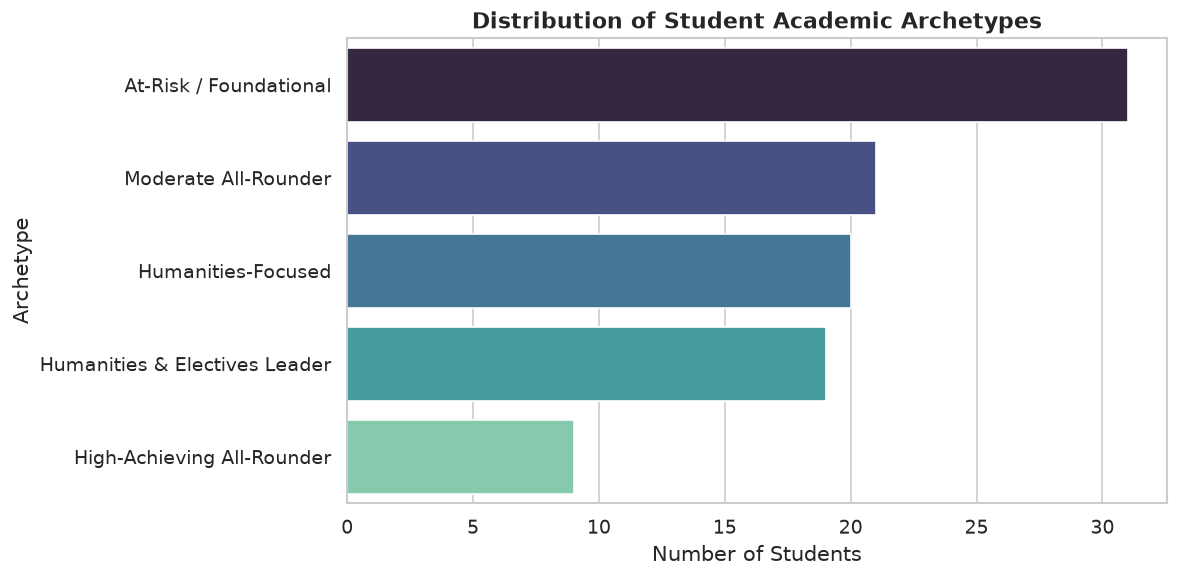

In [12]:
# Segment students into natural preliminary cohorts
conditions = [
    (df_domains["STEM_Avg"] >= 75) & (df_domains["Humanities_Avg"] >= 75),
    (df_domains["Humanities_Avg"] >= 65) & (df_domains["STEM_Avg"] < 65) & (df_domains["Electives_Avg"] >= 70),
    (df_domains["Humanities_Avg"] >= 65) & (df_domains["STEM_Avg"] < 65) & (df_domains["Electives_Avg"] < 70),
    (df_domains["Overall_Core_Avg"] < 50)
]
choices = [
    "High-Achieving All-Rounder",
    "Humanities & Electives Leader",
    "Humanities-Focused",
    "At-Risk / Foundational"
]

df_domains["Preliminary_Cohort"] = np.select(conditions, choices, default="Moderate All-Rounder")

cohort_counts = df_domains["Preliminary_Cohort"].value_counts()
print("=== Preliminary Student Cohorts (Pre-Clustering) ===")
display(cohort_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=cohort_counts.values, y=cohort_counts.index, palette="mako")
plt.title("Distribution of Student Academic Archetypes", fontsize=13, fontweight="bold")
plt.xlabel("Number of Students")
plt.ylabel("Archetype")
plt.tight_layout()
plt.show()


---
## 7. Scaling Feasibility: Why Standardization is Critical



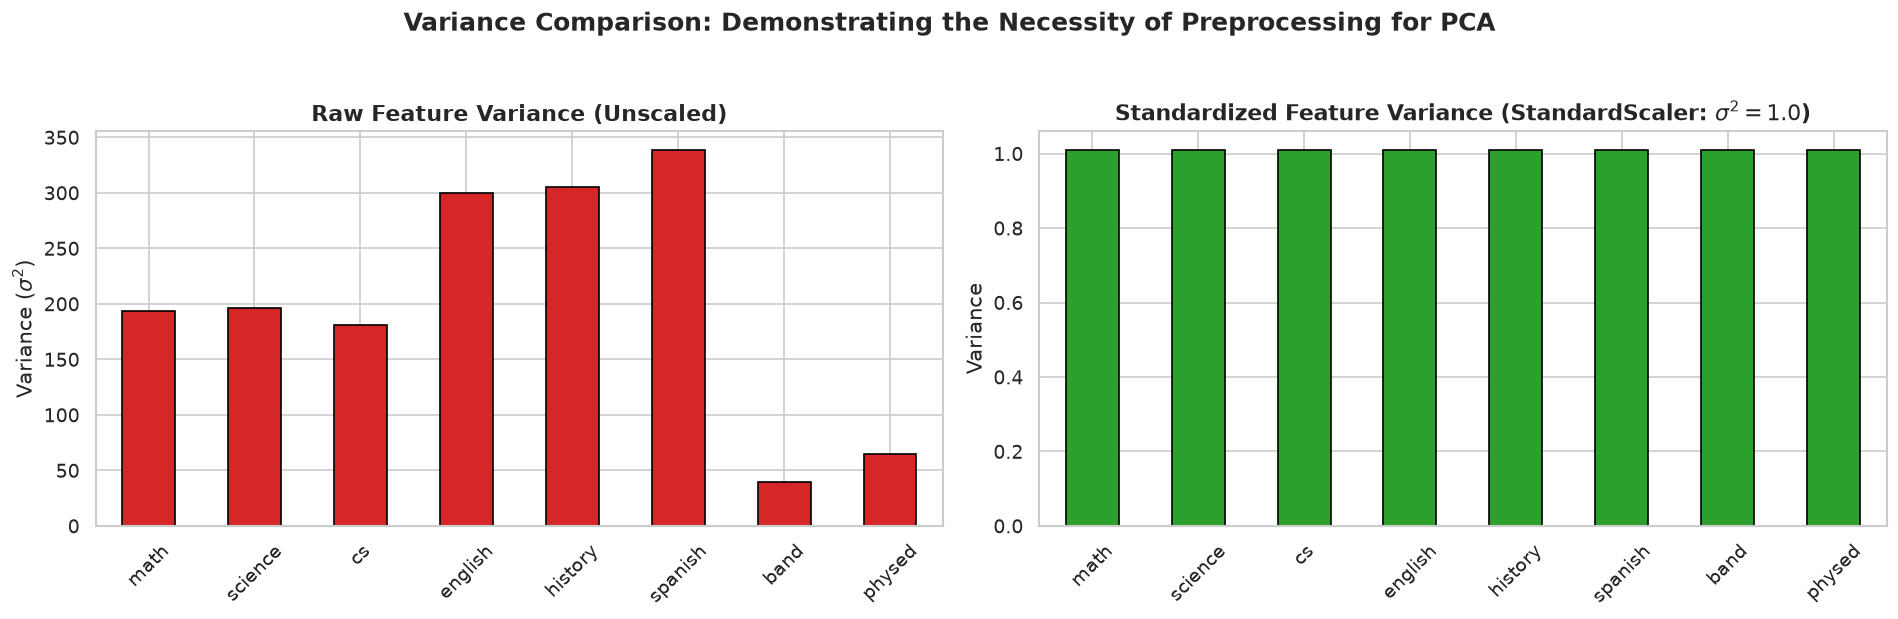

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = pd.DataFrame(scaler.fit_transform(df[ALL_SUBJECTS]), columns=ALL_SUBJECTS)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Raw Variance
df[ALL_SUBJECTS].var().plot(kind="bar", ax=axes[0], color="#d62728", edgecolor="black")
axes[0].set_title("Raw Feature Variance (Unscaled)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Variance ($\sigma^2$)")
axes[0].set_xticklabels(ALL_SUBJECTS, rotation=45)

# Standardized Variance
scaled_data.var().plot(kind="bar", ax=axes[1], color="#2ca02c", edgecolor="black")
axes[1].set_title("Standardized Feature Variance (StandardScaler: $\\sigma^2 = 1.0$)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Variance")
axes[1].set_xticklabels(ALL_SUBJECTS, rotation=45)

plt.suptitle("Variance Comparison: Demonstrating the Necessity of Preprocessing for PCA", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


---
## 8. EDA Synthesis & Bridge to Dimensionality Reduction

### Summary of Key Findings:
| Finding | Statistical Evidence | Impact on PCA / t-SNE |
| :--- | :--- | :--- |
| **Collinear Blocks** | $r_{\text{STEM}} \ge 0.97$, $r_{\text{Hum}} \ge 0.96$ | Data dimensionality can be compressed from 8D to 2D/3D with minimal information loss ($>95\%$ variance explained). |
| **Elective Orthogonality** | $r_{\text{Core, Electives}} \approx 0.05$ | Electives will form their own independent principal component (expected **PC2**). |
| **Variance Disparities** | Humanities $\sigma \approx 18$, Electives $\sigma \approx 6$ | Z-score scaling is non-negotiable to prevent Humanities from dominating the eigenvector calculation. |
| **Cohort Separation** | At-risk students ($n \approx 44$) cluster far from elite all-rounders ($n \approx 9$). | Non-linear manifold learning (t-SNE / UMAP) is expected to cleanly preserve these clusters in 2D. |

---
### Next Steps:
1. Proceed to **`02_PCA_Analysis.ipynb`** for Eigenvector decomposition, Scree plots, 2D/3D PCA visualization, and K-Means clustering.
2. Proceed to **`03_tSNE_Analysis.ipynb`** for hyperparameter tuning (perplexity, learning rate) and quantitative Silhouette score benchmarking against PCA.
